In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Задача 1. Анализ A/B теста по GMV

Компания CentralProducts занимается онлайн-продажей офисных принадлежностей.

Был запущен A/B тест, в рамках которого был протестирован новый дизайн приложения с дополнительными предложениями к корзине товаров.

Предполагается, что данная механика должна поднять GMV (Gross Merchandise Value, т.е. суммарный клиентский чек за определённый период времени).

Необходимо рассчитать результаты A/B теста, а также сегментировать результаты.

## Пункт 1. Импорт данных

Импортируй файл *CentralProducts_GMV_data.csv*

 - *id_client* - идентификатор клиента;
 - *exp_group* - экспериментальная группа;
 - *marketing_channel* - маркетинговый канал привлечения данного клиента;
 - *gmv*;

Выведи первые и последние 5 строк датасета.

Выведи реализации выборочных средних переменной `gmv` отдельно для групп  А и В, а также размеры выборок для А и B.

In [ ]:
# Загружаем данные
df = pd.read_csv('CentralProducts_GMV_data.csv')
df.head()

,id_client,exp_group,marketing_channel,gmv
0,102835,test,organic,3226
1,102558,test,ad_feed,2588
2,100324,test,organic,2425
3,100755,control,ad_feed,817
4,102567,control,ad_feed,9024


In [ ]:
# Отделяем группы
a = df[df['exp_group'] == 'control']['gmv'].values
b = df[df['exp_group'] == 'test']['gmv'].values

print(f"Размер группы A: {len(a)}")
print(f"Размер группы B: {len(b)}")
print(f"Среднее A: {np.mean(a):.2f}")
print(f"Среднее B: {np.mean(b):.2f}")

Размер группы A: 1553
Размер группы B: 1448
Среднее A: 2750.89
Среднее B: 3223.06


## Пункт 2. Ручной расчёт доверительного интервала для разницы средних

Построй реализацию асимптотического доверительного интервала надежности $0.95$ для разницы средних групп В и А.

Формулу для расчёта границ доверительного интервала напиши самостоятельно.

In [ ]:
diff_mean = np.mean(b) - np.mean(a)
print(f"Разница средних (B-A): {diff_mean:.4f}")

# alpha = 0.05
se_a = np.std(a, ddof=1) / np.sqrt(len(a))
se_b = np.std(b, ddof=1) / np.sqrt(len(b))
se_diff = np.sqrt(se_a**2 + se_b**2)
print(f"Стандартная ошибка разницы: {se_diff:.4f}")

z_crit = stats.norm.ppf(0.975) # 1 - \alpha / 2
print(f"z-критическое: {z_crit:.4f}")

lower_man = diff_mean - z_crit * se_diff
upper_man = diff_mean + z_crit * se_diff

print(f"95% ДИ для разницы средних: [{lower_man:.4f}, {upper_man:.4f}]")

Разница средних (B-A): 472.1708
Стандартная ошибка разницы: 81.4018
z-критическое: 1.9600
95% ДИ для разницы средних: [312.6262, 631.7154]


## Пункт 3. Автоматический расчёт доверительного интервала для разницы средних

Получи те же результаты, что и в предыдущем пункте, используя функцию *interval*.



In [ ]:
ci_mean = stats.norm.interval(
    confidence=0.95,
    loc=diff_mean,
    scale=se_diff
)

print(f"Разница средних: {diff_mean:.4f}")
print(f"95% ДИ через z.interval: [{ci_mean[0]:.4f}, {ci_mean[1]:.4f}]")

Разница средних: 472.1708
95% ДИ через z.interval: [312.6262, 631.7154]


## Пункт 4. Расчёт доверительного интервала для разницы средних с помощью бутстрапа

Получи те же результаты, что и в предыдущем пункте, используя бутстрап.

Число бутстрап выборок (псевдовыборок) выбери самостоятельно.

Сравни интервалы, полученные в Заданиях 3 и 4.


In [ ]:
n_iter = 1000
boot_diffs_mean = []

for _ in range(n_iter):
    boot_a = np.random.choice(a, size=len(a), replace=True)
    boot_b = np.random.choice(b, size=len(b), replace=True)
    boot_diffs_mean.append(np.mean(boot_b) - np.mean(boot_a))

lower_boot_mean = np.percentile(boot_diffs_mean, 2.5)
upper_boot_mean = np.percentile(boot_diffs_mean, 97.5)

print(f"Разница средних: {diff_mean:.4f}")
print(f"95% ДИ (бутстрап): [{lower_boot_mean:.4f}, {upper_boot_mean:.4f}]")
print(f"95% ДИ (z-тест): [{lower_man:.4f}, {upper_man:.4f}]")

Разница средних: 472.1708
95% ДИ (бутстрап): [308.1751, 633.6842]
95% ДИ (z-тест): [312.6262, 631.7154]


## Пункт 5. Расчёт доверительного интервала для разницы медиан с помощью бутстрапа

С помощью бутстрапа рассчитай границы доверительного интервала для разницы медиан в группах А и В.

In [ ]:
median_a = np.median(a)
median_b = np.median(b)
diff_median = median_b - median_a

print(f"Медиана A: {median_a:.2f}")
print(f"Медиана B: {median_b:.2f}")
print(f"Разница медиан: {diff_median:.4f}")

Медиана A: 2352.00
Медиана B: 2790.00
Разница медиан: 438.0000


In [ ]:
boot_diffs_median = []

for _ in range(n_iter):
    boot_a = np.random.choice(a, size=len(a), replace=True)
    boot_b = np.random.choice(b, size=len(b), replace=True)
    boot_diffs_median.append(np.median(boot_b) - np.median(boot_a))

lower_boot_median = np.percentile(boot_diffs_median, 2.5)
upper_boot_median = np.percentile(boot_diffs_median, 97.5)

print(f"95% ДИ для разницы медиан: [{lower_boot_median:.4f}, {upper_boot_median:.4f}]")

if lower_boot_median > 0:
    print("Медиана B значимо больше медианы A")
elif upper_boot_median < 0:
    print("Медиана B значимо меньше медианы A")
else:
    print("Разница медиан не значима")

95% ДИ для разницы медиан: [272.9750, 633.0500]
Медиана B значимо больше медианы A


## Пункт 6. Автоматизация бутстрапа

Напиши функцию *bootstrap_ci*, которая берёт на вход:

 - Два массива данных;
 - Агрегирующую функцию, для которой совершается бутстрап (среднее/медиана/...);
 - Количество итераций (со значением по умолчанию $1000$);
 - Уровень значимости со значением по умолчанию $5\%$;

На выходе:

 - Левая и правая границы доверительного интервала, полученные методом бутстрапа;
 - График-гистограмма полученных бутстрапом разностей с отмеченными вертикальными линиями нулём и серединой интервала.

In [ ]:
def bootstrap_ci(a, b, func, n_iter=1000, alpha=.05):
    diffs = []
    for _ in range(n_iter):
        boot_a = np.random.choice(a, size=len(a), replace=True)
        boot_b = np.random.choice(b, size=len(b), replace=True)
        diffs.append(func(boot_b) - func(boot_a))

    low = np.percentile(diffs, 100*alpha/2)
    high = np.percentile(diffs, 100*(1-alpha/2))

    # Визуализация
    plt.figure(figsize=(8, 4))
    plt.hist(diffs, bins=30, edgecolor='black', alpha=0.7)
    plt.axvline(low, color='red', linestyle='--', label=f'{alpha/2*100:.1f}%: {low:.2f}')
    plt.axvline(high, color='red', linestyle='--', label=f'{(1-alpha/2)*100:.1f}%: {high:.2f}')
    plt.axvline(0, color='black', linestyle='-', label='0')
    plt.axvline(np.mean(diffs), color='blue', linestyle='-', label=f'среднее: {np.mean(diffs):.2f}')
    plt.title(f'Бутстрап распределение разницы {func.__name__}')
    plt.xlabel('Разница (B-A)')
    plt.ylabel('Частота')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return np.percentile(diffs, 100*alpha/2), np.percentile(diffs, 100*(1-alpha/2))

## Пункт 7. Сегментация доверительного интервала

Рассмотрим продажи в разных сегментах.

Для создания новых выборок используй переменную `marketing_channel`.

Общее количество выборок: 2 $\times$ "количество маркетинговых каналов".

Примени *функцию* *bootstrap_ci* для расчёта границ доверительного интервала для разницы средних и медиан для групп B и A в каждом сегменте по отдельности.

Какие выводы можно сделать о продажах в сегментах по отдельности и о всей ситуации в целом?

In [ ]:
df.head()

,id_client,exp_group,marketing_channel,gmv
0,102835,test,organic,3226
1,102558,test,ad_feed,2588
2,100324,test,organic,2425
3,100755,control,ad_feed,817
4,102567,control,ad_feed,9024



organic:


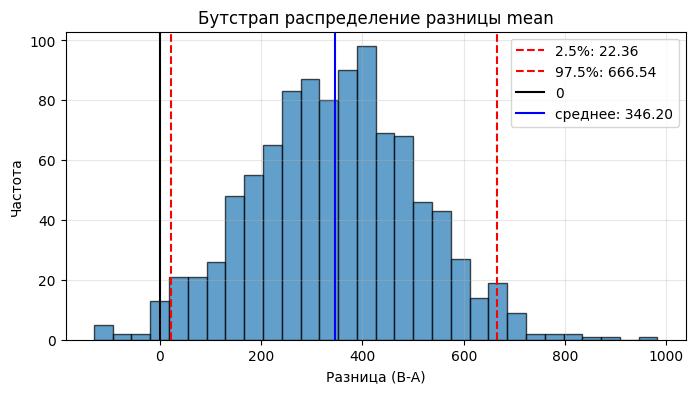

  Среднее: B-A = 337.6, ДИ [22.4, 666.5]


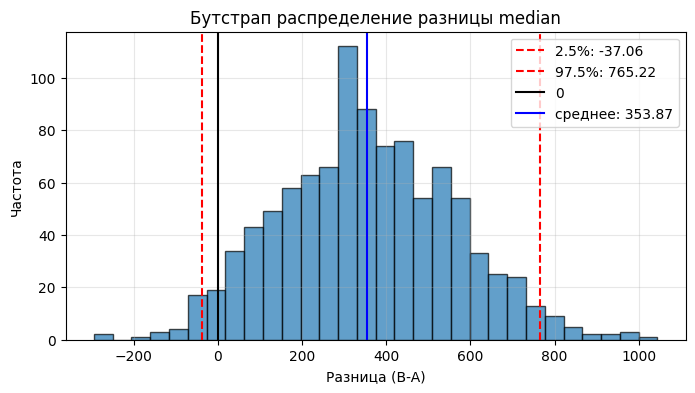

  Медиана: B-A = 365.5, ДИ [-37.1, 765.2]

ad_feed:


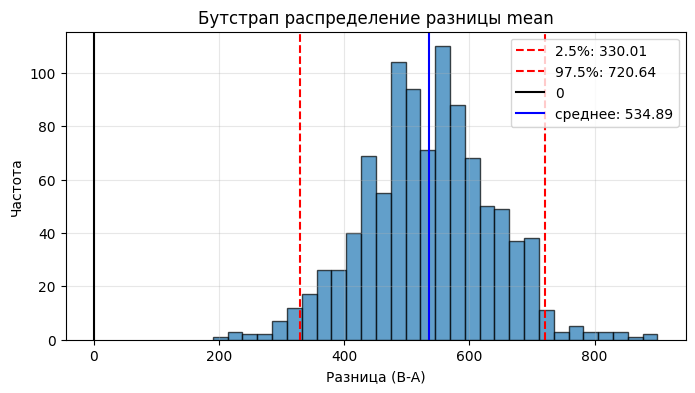

  Среднее: B-A = 535.3, ДИ [330.0, 720.6]


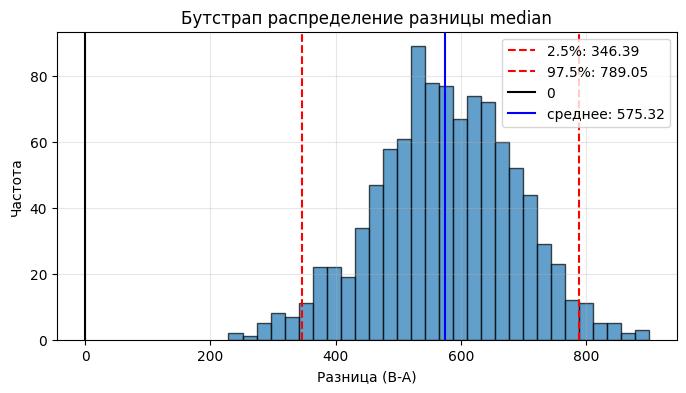

  Медиана: B-A = 587.5, ДИ [346.4, 789.0]

email:


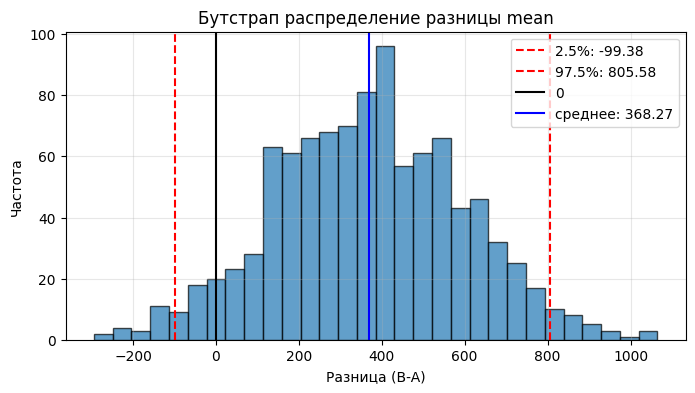

  Среднее: B-A = 358.4, ДИ [-99.4, 805.6]


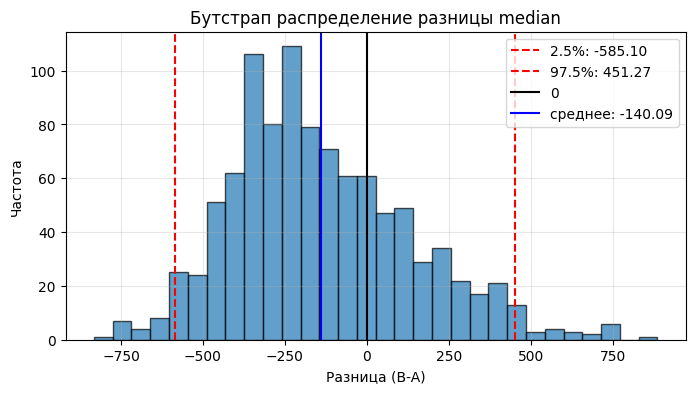

  Медиана: B-A = -205.0, ДИ [-585.1, 451.3]


In [ ]:
for i in df['marketing_channel'].unique():
    print(f"\n{i}:")

    a = df[(df['marketing_channel']==i) & (df['exp_group']=='control')]['gmv'].values
    b = df[(df['marketing_channel']==i) & (df['exp_group']=='test')]['gmv'].values

    # Разница средних
    low_m, high_m = bootstrap_ci(a, b, np.mean)
    print(f"  Среднее: B-A = {np.mean(b)-np.mean(a):.1f}, ДИ [{low_m:.1f}, {high_m:.1f}]")

    # Разница медиан
    low_md, high_md = bootstrap_ci(a, b, np.median)
    print(f"  Медиана: B-A = {np.median(b)-np.median(a):.1f}, ДИ [{low_md:.1f}, {high_md:.1f}]")

# Пуассоновский бутстрап

## Мультиномиальное распределение

**Вспомним мультиномиальное распределение**

Пусть проводится $n$ независимых испытаний, и в каждом испытании объект попадает ровно в одну из $m$ категорий с вероятностями

$$
p_1, p_2, \dots, p_m, \qquad \sum_{i=1}^{m} p_i = 1
$$

Тогда случайный вектор счётчиков

$$
(N_1, N_2, \dots, N_m)
$$

имеет мультиномиальное распределение:

$$
(N_1, N_2, \dots, N_m) \sim \mathrm{Multinomial}(n; p_1, p_2, \dots, p_m)
$$

где

- $N_i$ — число попаданий в категорию $i$
- $\sum_{i=1}^{m} N_i = n$

Функция вероятности:

$$
P(N_1=n_1, \dots, N_m=n_m)
=
\frac{n!}{n_1! n_2! \dots n_m!}
p_1^{n_1} p_2^{n_2} \dots p_m^{n_m}
$$

при условиях

$$
n_i \ge 0, \qquad \sum_{i=1}^{m} n_i = n
$$

Математическое ожидание и дисперсия для каждой компоненты:

$$
\mathbb{E}[N_i] = n p_i
$$

$$
\mathrm{Var}(N_i) = n p_i (1 - p_i)
$$


## Классический бутстрап и его связь с мультиномиальным распределением

Пусть есть выборка

$$
X_1, X_2, \dots, X_n
$$

Классический бутстрап на каждой итерации строит новую выборку размера $n$ с возвращением из исходных $n$ наблюдений.

То есть каждому наблюдению ставится в соответствие вес:

$$
(W_1, W_2, \dots, W_n)
$$

где

$$
(W_1, W_2, \dots, W_n) \sim \mathrm{Multinomial}\left(n; \frac{1}{n}, \frac{1}{n}, \dots, \frac{1}{n}\right)
$$

Свойства таких весов:

$$\sum_{i=1}^{n} W_i = n$$

$$\mathbb{E}[W_i] = 1$$

$$\mathbb{D}(W_i) = 1 - \frac{1}{n}$$


В классическом бутстрапе веса **зависимы**:

Если один объект появился много раз, то другим объектам остаётся меньше места, потому что суммарный размер бутстрап-выборки равен $n$.

## Пуассоновский бутстрап

В пуассоновском бутстрап каждому наблюдению независимо назначается случайный вес

$$W_i \sim \mathcal{P}(1), \qquad i=1,2,\dots,n$$

причём веса $W_1, W_2, \dots, W_n$ **независимы**.

Тогда бутстрап-статистика считается как взвешенная статистика по исходной выборке с весами $W_i$.

Например, пуассоновская бутстрап-оценка среднего:

$$\bar{X}_{\mathcal{P}}=\frac{\sum_{i=1}^{n} W_i X_i}{\sum_{i=1}^{n} W_i}$$

Свойства весов:

$$\mathbb{E}[W_i] = 1$$

$$\mathrm{Var}(W_i) = 1$$

Если

$$W_i \sim \mathcal{P}(\lambda)$$

Тогда:

$$\mathbb{E}[W_i] = \lambda$$
$$\mathbb{D}(W_i) = \lambda$$

В стандартном варианте берётся $\lambda = 1$.

# Задача 2. Анализ A/B теста с помощью пуассоновского бутстрапа

## Задание 1. Импорт и предобработка данных

- Импортируй датасет *Data_PoissonBootstrap.csv*;

- Выведи суммарное кол-во наблюдений, а также кол-во наблюдений в каждой группе;

- Рассчитай среднее значение поля *revenue* в каждой группе;

- Построй гистограмму клиентских чеков по группам, исключив нули из выборки;

**Описание датасета**

 - *user_id* - уникальный идентификатор пользователя;
 - *group* - экспериментальная группа;
 - *revenue* - клиентские траты за период времени;

In [ ]:
df = pd.read_csv('Data_PoissonBootstrap.csv')

In [ ]:
df.head()

,user_id,group,revenue
0,1,control,0
1,2,treatment,0
2,3,control,0
3,4,control,0
4,5,control,0


In [ ]:
print(len(df))

200000


In [ ]:
arpu_by_group = df.groupby('group')['revenue'].mean()
arpu_by_group

,revenue
group,
control,1.951797
treatment,1.948861


In [ ]:
observed_diff = arpu_by_group['treatment'] - arpu_by_group['control']
observed_diff

np.float64(-0.002935500095544885)

In [ ]:
control = df[df['group'] == 'control']['revenue'].to_numpy()
treatment = df[df['group'] == 'treatment']['revenue'].to_numpy()

In [ ]:
print(len(control))
print(len(treatment))

100076
99924


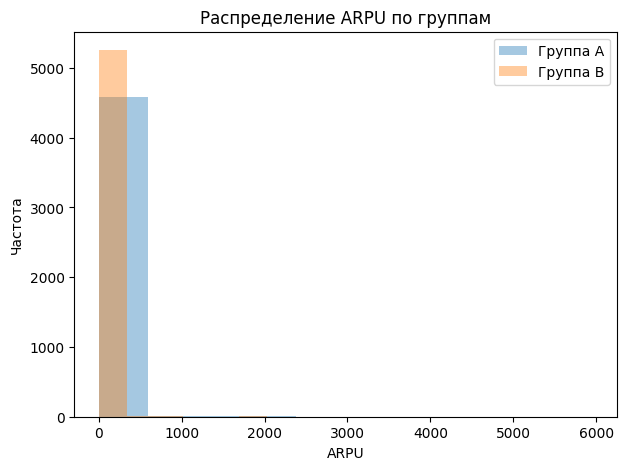

In [ ]:
plt.figure(figsize=(7, 5))
plt.hist(control[control != 0], alpha=0.4, label='Группа А')
plt.hist(treatment[treatment != 0], alpha=0.4, label='Группа В')
plt.xlabel('ARPU')
plt.ylabel('Частота')
plt.title('Распределение revenue по группам')
plt.legend()
plt.show()

**Вывод**

У распределений в обеих группах длинный и малочастотный правый хвост.

## Задание 2. Классический бутстрап

Рассчитай границы доверительного интервала разницы средних с помощью классического бутстрапа.

In [ ]:
np.random.seed(999)
n_iter = 2000
ordinary_diffs = []

for _ in range(n_iter):
    control_sample = np.random.choice(control, size=len(control), replace=True)
    treatment_sample = np.random.choice(treatment, size=len(treatment), replace=True)
    ordinary_diffs.append(treatment_sample.mean() - control_sample.mean())

ordinary_diffs = np.array(ordinary_diffs)
ordinary_diffs[:5]

array([-0.05967487,  0.04709142,  0.01494629,  0.02856394,  0.01830025])

In [ ]:
ordinary_ci = np.percentile(ordinary_diffs, [2.5, 97.5])

In [ ]:
print('Разница:', observed_diff)
print('Бутрстрап-среднее разниц:', ordinary_diffs.mean())
print('Доверительный интервал 95%:', ordinary_ci)

Разница: -0.002935500095544885
Бутрстрап-среднее разниц: -0.0012261843218440611
Доверительный интервал 95%: [-0.3110192   0.28339578]


## Задание 3. Пуассоновский бутстрап

Рассчитай границы доверительного интервала разницы средних с помощью пуассоновского бутстрапа.

**Создадим один пример вектора пуассоновских весов и визуализируем его на гистограмме**

In [ ]:
poisson_weights = np.random.poisson(1, size=len(control))

print(type(poisson_weights))
print(poisson_weights[:5])

<class 'numpy.ndarray'>
[2 0 1 2 0]


Следует ещё ввести проверку на то, не получились ли все веса равными нулю. Это крайне маловероятно, но теоретически возможно.

In [ ]:
print(poisson_weights.sum())

99613


Теперь перейдём к гистограмме

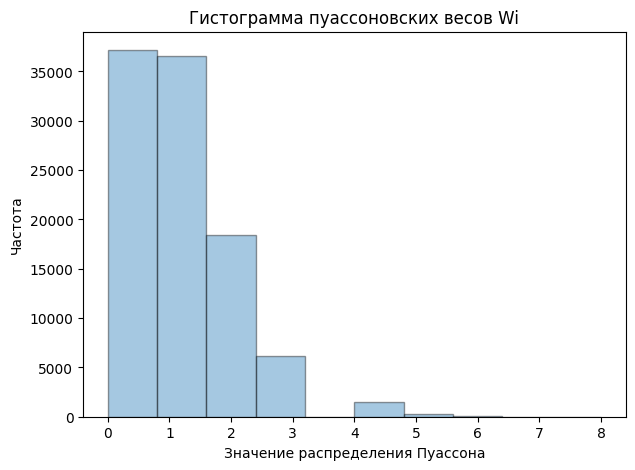

In [ ]:
plt.figure(figsize=(7, 5))
plt.hist(poisson_weights, alpha=0.4, edgecolor='black')
plt.xlabel('Значение распределения Пуассона')
plt.ylabel('Частота')
plt.title('Гистограмма пуассоновских весов Wi')
plt.show()

**Перейдём к пуассоновскому бутстрапу**

In [ ]:
np.random.seed(999)
poisson_diffs = []

for _ in range(n_iter):
    w_control = np.random.poisson(1, size=len(control))
    w_treatment = np.random.poisson(1, size=len(treatment))

    if w_control.sum() + w_treatment.sum() > 0:

        control_mean = (control * w_control).sum() / w_control.sum()
        treatment_mean = (treatment * w_treatment).sum() / w_treatment.sum()

        poisson_diffs.append(treatment_mean - control_mean)

poisson_diffs = np.array(poisson_diffs)
poisson_diffs[:5]

array([-0.01874175,  0.22654575,  0.06810834, -0.1651206 ,  0.0252993 ])

In [ ]:
poisson_ci = np.percentile(poisson_diffs, [2.5, 97.5])

In [ ]:
print('Разница:', observed_diff)
print('Бутрстрап-среднее разниц:', poisson_diffs.mean())
print('Доверительный интервал 95%:', poisson_ci)

Разница: -0.002935500095544885
Бутрстрап-среднее разниц: 0.0008163054985417563
Доверительный интервал 95%: [-0.28439974  0.28464047]


## Сравнение результатов

На одной гистограмме визуализируй разницы средних, полученные классическим и пуассоновским бутстрапом.

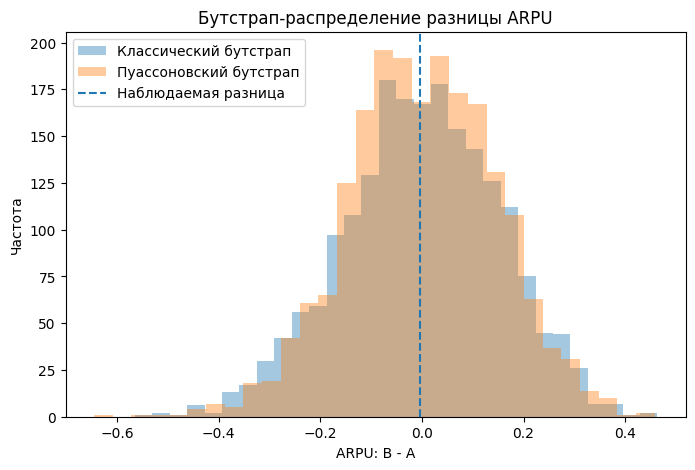

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(ordinary_diffs, bins=30, alpha=0.4, label='Классический бутстрап')
plt.hist(poisson_diffs, bins=30, alpha=0.4, label='Пуассоновский бутстрап')
plt.axvline(observed_diff, linestyle='--', label='Наблюдаемая разница')
plt.xlabel('ARPU: B - A')
plt.ylabel('Частота')
plt.title('Бутстрап-распределение разницы ARPU')
plt.legend()
plt.show()

## Вывод

В этой задаче классический бутстрап и пуассоновский бутстрап дают близкие оценки распределения разности ARPU между группами.

Однако пуассоновский бутстрап удобнее концептуально и вычислительно для больших продуктовых данных, потому что:

1. не требует явно пересэмплировать пользователей в выборку размера $n$
2. работает через независимые веса $W_i \sim \mathcal{P}(1)$

Именно поэтому в реальных аналитических системах и large-scale A/B-тестах пуассоновский бутстрап часто оказывается предпочтительнее классического.


Ещё один важный плюс пуассоновского бутстрапа заключается в том, что  при добавлении новых наблюдений (инкрементальный сценарий) нам не придётся создавать все пвседовыборки заново.

Для обычного бутстрепа нам все нужно начинать с начала, а в пуассоновском случае мы можем создать только новые веса и пересчитать оценки.

**Теперь сравним время выполнения алгоритмов**

In [ ]:
n_iter_big = 10000

In [ ]:
%%time

ordinary_diffs_big = []

for _ in range(n_iter_big):
    control_sample = np.random.choice(control, size=len(control), replace=True)
    treatment_sample = np.random.choice(treatment, size=len(treatment), replace=True)
    ordinary_diffs_big.append(treatment_sample.mean() - control_sample.mean())

ordinary_diffs_big = np.array(ordinary_diffs_big)

CPU times: user 56.6 s, sys: 173 ms, total: 56.8 s
Wall time: 1min 1s


In [ ]:
%%time

poisson_diffs_big = []

for _ in range(n_iter_big):
    w_control = np.random.poisson(1, size=len(control))
    w_treatment = np.random.poisson(1, size=len(treatment))

    control_mean = (control * w_control).sum() / w_control.sum()
    treatment_mean = (treatment * w_treatment).sum() / w_treatment.sum()

    poisson_diffs_big.append(treatment_mean - control_mean)

poisson_diffs_big = np.array(poisson_diffs_big)

CPU times: user 2min 18s, sys: 308 ms, total: 2min 19s
Wall time: 2min 29s


**Почему обычный бутстрап оказался быстрее?**

Обычный бутстрап оказался быстрее пуассоновского бутстрапа по времени выполнения.

- в обычном бутстрапе используются оптимизированные операции `np.random.choice` и `mean`;

- в пуассоновском бутстрапе на каждой итерации дополнительно выполняются:
    - генерация весов;
    - поэлементные умножения;
    - несколько операций суммирования;

**Преимущество пуассоновского бутстрапа на реальных задачах**

 - Не требует явного хранения бутстрап-выборок как отдельных таблиц;
 - Хорошо подходит для распределённых вычислений;

# Задача 3. Анализ разброса цен на недвижимость по районам города

**Цель**

Исследовать поведение цен на недвижимость в разных районах города.

**Задача**

1. **Предобработка данных**:
   - обработка пропущенных значений;
   - идентификация и удаление выбросов;
   - проверка распределения цен по районам.

2. **Статистический анализ**:
   - построить $95\%$-ный доверительный интервал для дисперсии цен по всем районам;
   - сравнить доверительные интервалы дисперсии между районами.




Импортируй датасет **real_estate_prices**.

 - *id_estate*	— идентификатор недвижимости.
 - *district*	— район расположения недвижимости.
 - *price* — цена (млн руб.)


In [2]:
df = pd.read_csv('real_estate_prices.csv', sep=';')

df.head()

,Район,Цена_млн
0,Центральный,16.9
1,Центральный,19.6
2,Центральный,14.3
3,Центральный,14.3
4,Центральный,19.7


In [3]:
print(f"Исходный размер данных: {len(df)}")
print("Количество пропусков:", df['Цена_млн'].isna().sum())

Исходный размер данных: 168
Количество пропусков: 3


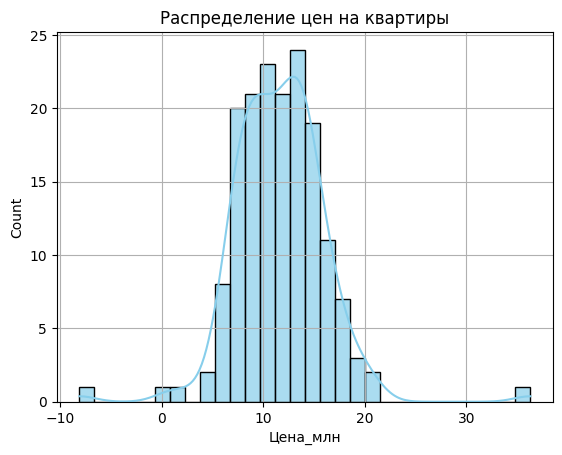

In [4]:
sns.histplot(df['Цена_млн'], kde=True, bins=30, color='skyblue', alpha=.7)
plt.title('Распределение цен на квартиры')
plt.grid()
plt.show()

In [5]:
print("Выбросы до очистки:")
print(df[~df['Цена_млн'].between(3, 20)])

Выбросы до очистки:
            Район  Цена_млн
29    Центральный      20.6
50    Центральный       NaN
54    Центральный      36.3
55    Центральный      -8.1
65       Спальный       NaN
111      Спальный       1.6
121  Бизнес-класс       NaN
166  Бизнес-класс      20.8
167  Бизнес-класс       0.6


In [6]:
# Очистка данных
clean_df = df[df['Цена_млн'].between(3, 20)].copy()

In [7]:
# Заполнение пропусков медианой по районам
for district in df['Район'].unique():
    district_median = clean_df[clean_df['Район'] == district]['Цена_млн'].median()
    clean_df.loc[(clean_df['Район'] == district) &
                (clean_df['Цена_млн'].isna()), 'Цена_млн'] = district_median

print(f"\nРазмер данных после очистки: {len(clean_df)}")


Размер данных после очистки: 159


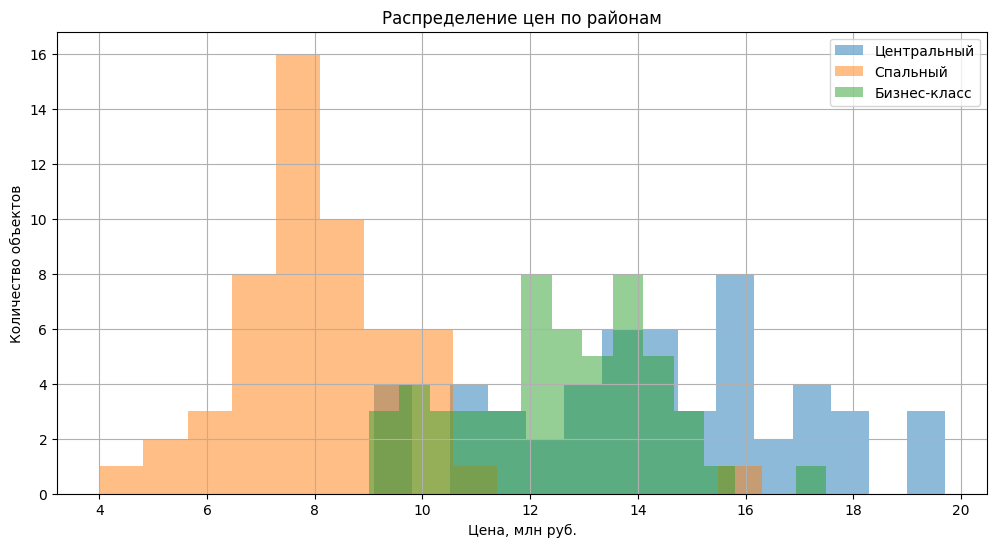

In [9]:
# Визуализация распределений
plt.figure(figsize=(12, 6))
for district in clean_df['Район'].unique():
    subset = clean_df[clean_df['Район'] == district]['Цена_млн']
    plt.hist(subset, bins=15, alpha=0.5, label=district)
plt.title('Распределение цен по районам')
plt.xlabel('Цена, млн руб.')
plt.ylabel('Количество объектов')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
def calculate_ci(data, confidence=0.99):
    n = len(data)
    mean = np.mean(data)
    sem = stats.sem(data)
    return stats.norm.interval(confidence, loc=mean, scale=sem)

In [11]:
# Функция для расчёта ДИ дисперсии
def variance_ci(data, confidence=0.95):
    n = len(data)
    s2 = np.var(data, ddof=1)
    chi2_low = stats.chi2.ppf((1 + confidence)/2, df=n-1)
    chi2_high = stats.chi2.ppf((1 - confidence)/2, df=n-1)
    return [(n-1)*s2/chi2_low, (n-1)*s2/chi2_high]

In [12]:
# Общий доверительный интервал дисперсии
overall_var = clean_df['Цена_млн'].var(ddof=1)
overall_ci = variance_ci(clean_df['Цена_млн'].values)
overall_ci

[np.float64(9.31594800430978), np.float64(14.49970246863603)]

In [13]:
districts = df['Район'].unique()

In [14]:
# Создаём словари для хранения результатов
clean_results = {}
raw_results = {}

# Расчёт для очищенных данных
for district in districts:
    dist_prices = clean_df[clean_df['Район'] == district]['Цена_млн']
    clean_results[district] = {
        'variance': dist_prices.var(ddof=1),
        'mean': np.mean(dist_prices),
        'ci_mean': calculate_ci(dist_prices),
        'ci': variance_ci(dist_prices),
        'n': len(dist_prices)
    }

# Расчёт для исходных данных (с выбросами)
for district in districts:
    dist_prices = df[df['Район'] == district]['Цена_млн']
    raw_results[district] = {
        'variance': dist_prices.var(ddof=1),
        'ci': variance_ci(dist_prices),
        'n': len(dist_prices)
    }

In [15]:
# Подготовка данных для визуализации

#ДИ для дисперсии (очищенные данные)
clean_vars = [clean_results[d]['variance'] for d in districts]
clean_ci_lower = [clean_results[d]['ci'][0] for d in districts]
clean_ci_upper = [clean_results[d]['ci'][1] for d in districts]

#ДИ для среднего (очищенные данные)
clean_mean = [clean_results[d]['mean'] for d in districts]
clean_ci_mean_lower = [clean_results[d]['ci_mean'][0] for d in districts]
clean_ci_mean_upper = [clean_results[d]['ci_mean'][1] for d in districts]

#ДИ для дисперсии (данные без чистки)
raw_vars = [raw_results[d]['variance'] for d in districts]
raw_ci_lower = [raw_results[d]['ci'][0] for d in districts]
raw_ci_upper = [raw_results[d]['ci'][1] for d in districts]

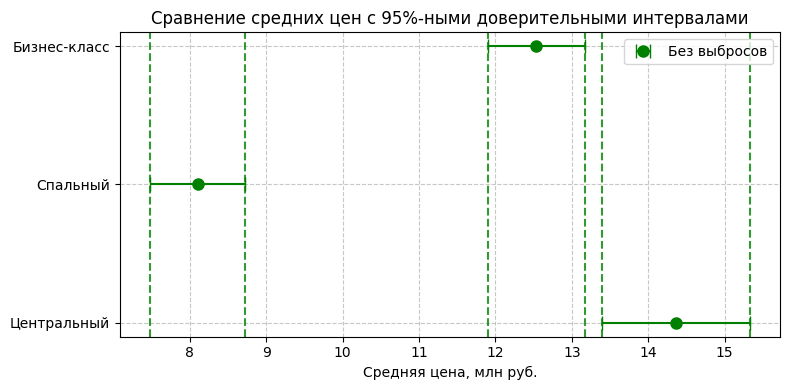

In [16]:
plt.figure(figsize=(8, 4))

# ДИ для средних
plt.errorbar(clean_mean, districts,
            xerr=[clean_mean[i]-clean_ci_mean_lower[i] for i in range(len(districts))],
            fmt='o', color='green', capsize=5, markersize=8,
            label='Без выбросов')

for lower, upper in zip(clean_ci_mean_lower, clean_ci_mean_upper):
    plt.axvline(lower, color='green', linestyle='--', alpha=0.8)
    plt.axvline(upper, color='green', linestyle='--', alpha=0.8)

plt.title('Сравнение средних цен с 95%-ными доверительными интервалами')
plt.xlabel('Средняя цена, млн руб.')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

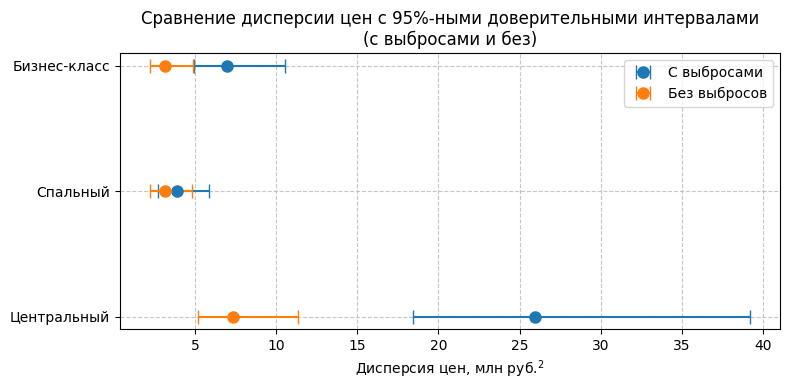

In [17]:
plt.figure(figsize=(8, 4))

# Исходные данные с выбросами
plt.errorbar(
    raw_vars,
    districts,
    xerr=[
        [raw_vars[i] - raw_ci_lower[i] for i in range(len(districts))],
        [raw_ci_upper[i] - raw_vars[i] for i in range(len(districts))]
    ],
    fmt='o',
    capsize=5,
    markersize=8,
    label='С выбросами'
)

# Очищенные данные
plt.errorbar(
    clean_vars,
    districts,
    xerr=[
        [clean_vars[i] - clean_ci_lower[i] for i in range(len(districts))],
        [clean_ci_upper[i] - clean_vars[i] for i in range(len(districts))]
    ],
    fmt='o',
    capsize=5,
    markersize=8,
    label='Без выбросов'
)

plt.title(
    'Сравнение дисперсии цен с 95%-ными доверительными интервалами\n'
    '(с выбросами и без)'
)
plt.xlabel('Дисперсия цен, млн руб.$^2$')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Вывод результатов
print("\nСравнение результатов:")
for district in districts:
    print(f"\nРайон {district}:")
    print(f"  Очищенные данные:")
    print(f"    Дисперсия: {clean_results[district]['variance']:.2f}")
    print(f"    95%-ный ДИ: [{clean_results[district]['ci'][0]:.2f}, {clean_results[district]['ci'][1]:.2f}]")
    print(f"    Объектов: {clean_results[district]['n']}")
    print(f"  Исходные данные (с выбросами):")
    print(f"    Дисперсия: {raw_results[district]['variance']:.2f}")
    print(f"    95%-ный ДИ: [{raw_results[district]['ci'][0]:.2f}, {raw_results[district]['ci'][1]:.2f}]")
    print(f"    Объектов: {raw_results[district]['n']}")


Сравнение результатов:

Район Центральный:
  Очищенные данные:
    Дисперсия: 7.37
    95%-ный ДИ: [5.18, 11.34]
    Объектов: 52
  Исходные данные (с выбросами):
    Дисперсия: 25.93
    95%-ный ДИ: [18.43, 39.18]
    Объектов: 56

Район Спальный:
  Очищенные данные:
    Дисперсия: 3.16
    95%-ный ДИ: [2.23, 4.82]
    Объектов: 54
  Исходные данные (с выбросами):
    Дисперсия: 3.87
    95%-ный ДИ: [2.75, 5.85]
    Объектов: 56

Район Бизнес-класс:
  Очищенные данные:
    Дисперсия: 3.19
    95%-ный ДИ: [2.25, 4.88]
    Объектов: 53
  Исходные данные (с выбросами):
    Дисперсия: 6.97
    95%-ный ДИ: [4.95, 10.53]
    Объектов: 56


**Выводы**

* Дисперсия по&nbsp;центральному району самая большая, а&nbsp;ДИ широкий&nbsp;— это свидетельствует о&nbsp;высокой неопределённости цен в&nbsp;этом районе.  
Интересный вариант для&nbsp;вложений, если не&nbsp;пугают риски.

* Спальный и&nbsp;бизнес-класс районы наиболее стабильны в&nbsp;плане цен. Хороший выбор, если покупать для&nbsp;жизни, а&nbsp;не&nbsp;для&nbsp;инвестиций (низкий потенциал изменения цены).

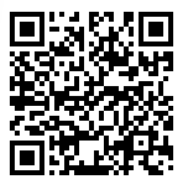